In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(0)

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone
sns.set(style='whitegrid')

import warnings
warnings.filterwarnings('ignore')

# Решающие деревья


## Визуализация

Рассмотрим три простых двумерных датасета, сгенерированных с помощью make_moons, make_circles и make_classification.

In [ ]:
from sklearn.datasets import make_moons, make_circles, make_classification

datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2,
                        class_sep=0.75, random_state=3, n_redundant=0)
]

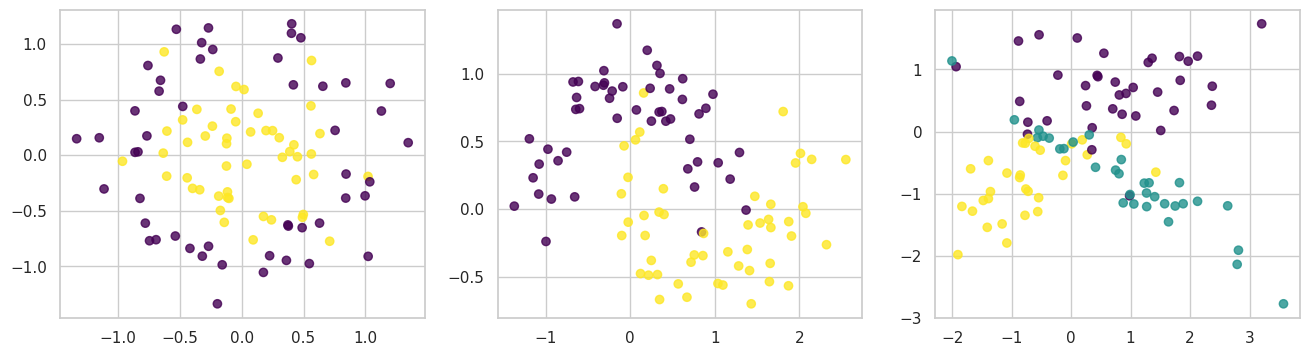

In [ ]:
plt.figure(figsize=(16, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap="viridis", alpha=0.8)

### Задание 1.


Разобьем на обучающую и тестовую выборки:


In [ ]:
from sklearn.model_selection import train_test_split

circles_X, circles_y = datasets[0]
circles_X_train, circles_X_test, circles_y_train, circles_y_test = train_test_split(
    circles_X, circles_y,
    test_size=0.2,
    random_state=42
)

moons_X, moons_y = datasets[1]
moons_X_train, moons_X_test, moons_y_train, moons_y_test = train_test_split(
    moons_X, moons_y,
    test_size=0.2,
    random_state=42
)

cls_X, cls_y = datasets[2]
cls_X_train, cls_X_test, cls_y_train, cls_y_test = train_test_split(
    cls_X, cls_y,
    test_size=0.2,
    random_state=42
)

Обучим модель для `circles`:

In [ ]:
dt_classifier = DecisionTreeClassifier()
dt_classifier.fit(circles_X_train, circles_y_train)

circles_y_pred_test = dt_classifier.predict(circles_X_test)
circles_y_pred_train = dt_classifier.predict(circles_X_train)

c_acc_test = accuracy_score(circles_y_test, circles_y_pred_test)
c_acc_train = accuracy_score(circles_y_train, circles_y_pred_train)

print(f'Circles accuracy:\n train - {c_acc_train},\n test - {c_acc_test}')

Circles accuracy:
 train - 1.0,
 test - 0.75


In [ ]:
def decision_boundary_plot(model, X, y):
  h = 0.02

  x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
  y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

  xx, yy = np.meshgrid(
      np.arange(x_min, x_max, h),
      np.arange(y_min, y_max, h)
  )

  Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
  Z = Z.reshape(xx.shape)

  plt.contourf(xx, yy, Z, alpha=0.3)
  plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k')

  plt.title("Decision Boundary")
  plt.show()

Разделяющие поверхности для `train`

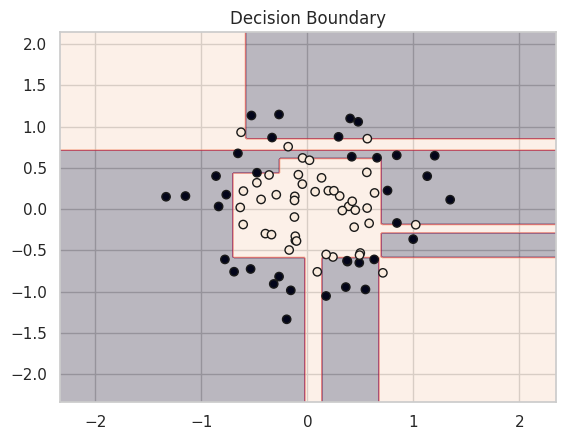

In [ ]:
decision_boundary_plot(dt_classifier, circles_X_train, circles_y_train)

Разделяющие поверхности для `test`

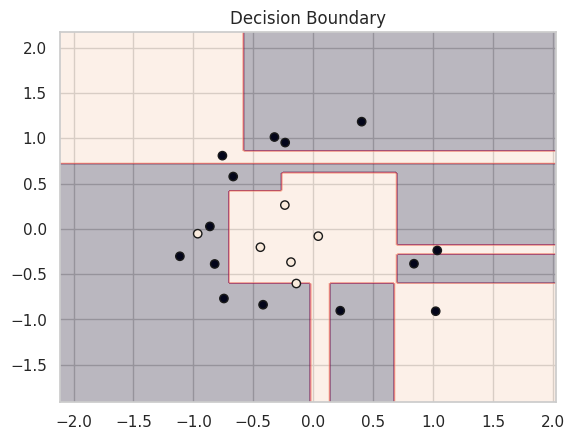

In [ ]:
decision_boundary_plot(dt_classifier, circles_X_test, circles_y_test)

Проделаем то же самое для `moons`:

In [ ]:
dt_classifier = DecisionTreeClassifier()
dt_classifier.fit(moons_X_train, moons_y_train)

moons_y_pred_test = dt_classifier.predict(moons_X_test)
moons_y_pred_train = dt_classifier.predict(moons_X_train)

m_acc_test = accuracy_score(moons_y_test, moons_y_pred_test)
m_acc_train = accuracy_score(moons_y_train, moons_y_pred_train)

print(f'Moons accuracy:\n train - {m_acc_train},\n test - {m_acc_test}')

Moons accuracy:
 train - 1.0,
 test - 0.95


Разделяющие поверхности для `train`

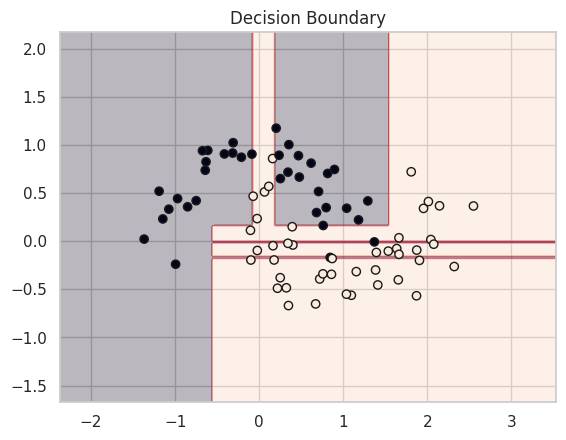

In [ ]:
decision_boundary_plot(dt_classifier, moons_X_train, moons_y_train)

Разделяющие поверхности для `test`

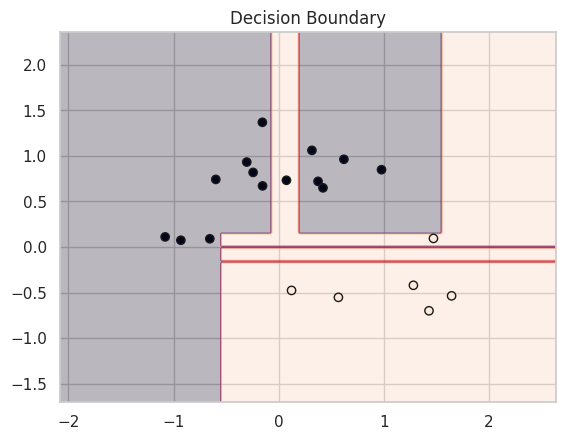

In [ ]:
decision_boundary_plot(dt_classifier, moons_X_test, moons_y_test)

И для `cls`:

In [ ]:
dt_classifier = DecisionTreeClassifier()
dt_classifier.fit(cls_X_train, cls_y_train)

cls_y_pred_test = dt_classifier.predict(cls_X_test)
cls_y_pred_train = dt_classifier.predict(cls_X_train)

cls_acc_test = accuracy_score(cls_y_test, cls_y_pred_test)
cls_acc_train = accuracy_score(cls_y_train, cls_y_pred_train)

print(f'Cls accuracy:\n train - {cls_acc_train},\n test - {cls_acc_test}')

Cls accuracy:
 train - 1.0,
 test - 0.65


Разделяющие поверхности для `train`

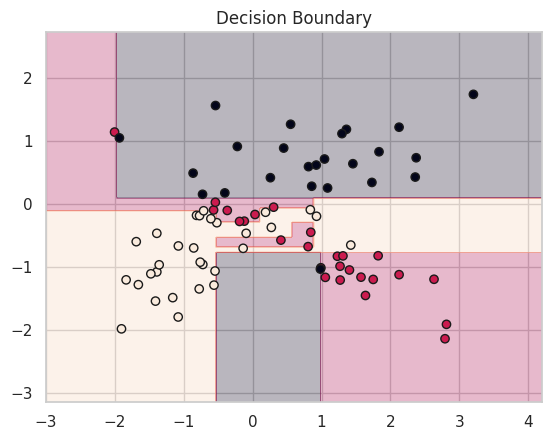

In [ ]:
decision_boundary_plot(dt_classifier, cls_X_train, cls_y_train)

Разделяющие поверхности для `test`

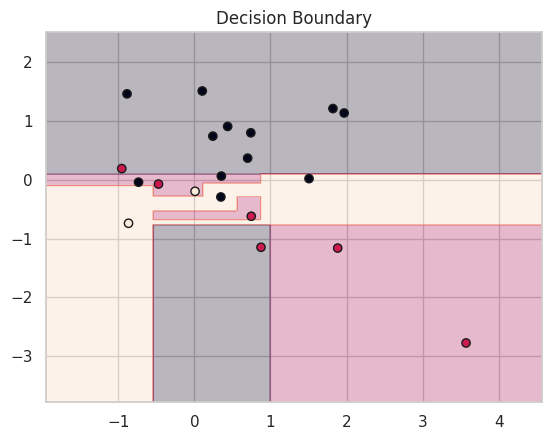

In [ ]:
decision_boundary_plot(dt_classifier, cls_X_test, cls_y_test)

В каждой выборке происходит переобучение на train, поскольку при параметрах по умолчанию (`max_depth = None`, `min_samples_split = 2`, `min_samples_leaf = 1`) дерево "дробит" пространство до идеальной классификации, тем самым подстраиваясь под каждое отдельное значение, а не ища закономерности.

### Задание 2.

Поработаем с `classification`, т.к. он дал худший результат на тесте.

Исследуем соотношение между `max_depth` и `min_samples_split`.

In [ ]:
res = []

depth = [1, 2, 3, 5, 7, None]

for ss in range(2, 11, 2):
  for d in depth:
    dt_classifier = DecisionTreeClassifier(max_depth=d, min_samples_split=ss)
    dt_classifier.fit(cls_X_train, cls_y_train)

    y_pred_test = dt_classifier.predict(cls_X_test)
    y_pred_train = dt_classifier.predict(cls_X_train)

    acc_test = accuracy_score(cls_y_test, y_pred_test)
    acc_train = accuracy_score(cls_y_train, y_pred_train)

    res.append({
        'max_depth': d,
        'min_samples_split': ss,
        'train_accuracy': acc_train,
        'test_accuracy': acc_test
    })

result = pd.DataFrame(res)

In [ ]:
result

,max_depth,min_samples_split,train_accuracy,test_accuracy
0,1.0,2,0.6625,0.50
1,2.0,2,0.8750,0.70
2,3.0,2,0.8875,0.70
3,5.0,2,0.9375,0.65
4,7.0,2,0.9625,0.65
5,NaN,2,1.0000,0.65
6,1.0,4,0.6625,0.50
7,2.0,4,0.8750,0.70
8,3.0,4,0.8875,0.70
9,5.0,4,0.9375,0.65


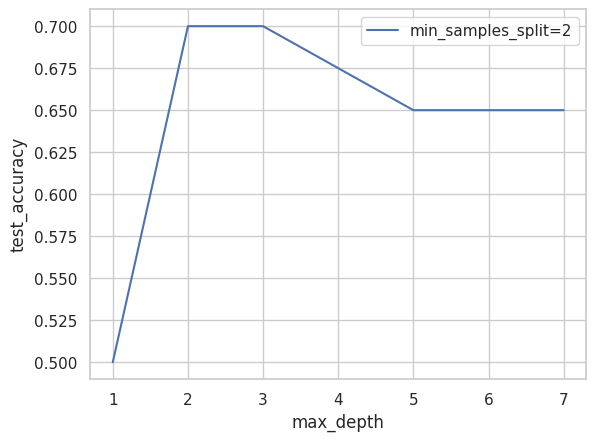

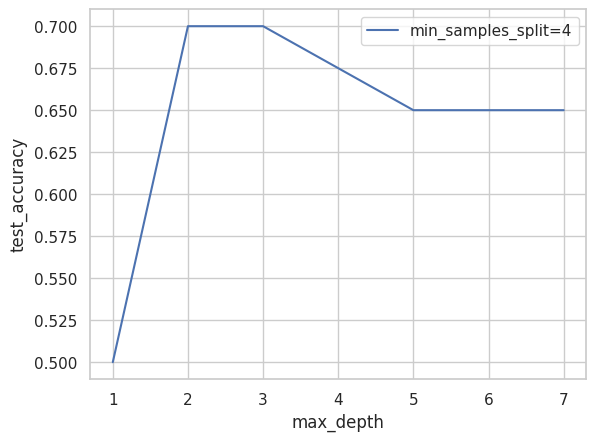

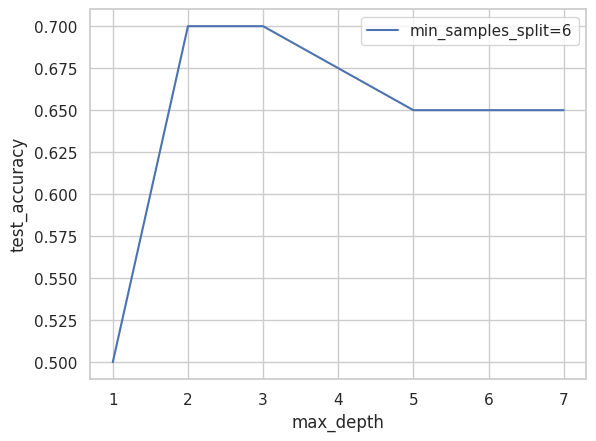

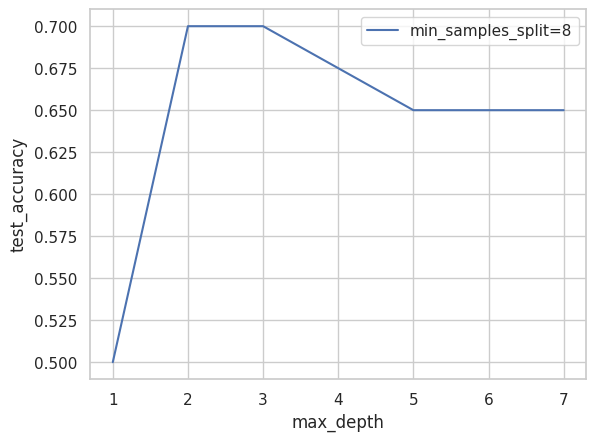

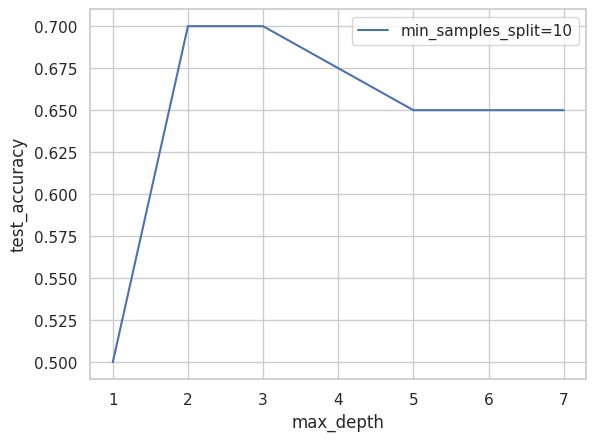

In [ ]:
for ss in result['min_samples_split'].unique():
  subset = result[result['min_samples_split'] == ss]

  plt.plot(
      subset['max_depth'],
      subset['test_accuracy'],
      label=f'min_samples_split={ss}'
  )

  plt.legend()
  plt.xlabel('max_depth')
  plt.ylabel('test_accuracy')
  plt.show()

**Выводы**

* Лучшее соотношение разброса и смещения наблюдается при `max_depth = 2-3`, на гракфиках видно, что при этих значениях наблюдаем максимальное качество на тесте;
* При меньшей глубине модель слишком простая -> недообучается. На графике видим низкое значение accuracy;
* При большей глубине модель переобучается - так же наблюдается снижение accuracy;
* Все графики (при разных значениях `min_samples_split`) получились абсолютно одинаковыми, из чего следует вывод, что данный параметр в выбранном диапазоне не оказывает значительного влияния на качество модели.

## Решающие деревья своими руками

### Задание 3

Реализация функции `find_best_split` из модуля `hw5code.py`:

In [ ]:
def find_best_split(feature_vector, target_vector):
    feature_vector = np.asarray(feature_vector)
    target_vector = np.asarray(target_vector)

    order = np.argsort(feature_vector)
    x = feature_vector[order]
    y = target_vector[order]

    mask = x[:-1] != x[1:]
    thresholds = (x[:-1][mask] + x[1:][mask]) / 2

    y = y.astype(int)

    left_count = np.arange(1, len(y))
    right_count = len(y) - left_count

    left_positive = np.cumsum(y)[:-1]
    right_positive = np.sum(y) - left_positive

    left_negative = left_count - left_positive
    right_negative = right_count - right_positive

    h_left = 1 - (left_positive / left_count) ** 2 - (left_negative / left_count) ** 2
    h_right = 1 - (right_positive / right_count) ** 2 - (right_negative / right_count) ** 2

    ginis = - (left_count / len(y)) * h_left - (right_count / len(y)) * h_right
    ginis = ginis[mask]

    best_idx = np.argmax(ginis)
    threshold_best = thresholds[best_idx]
    gini_best = ginis[best_idx]

    return thresholds, ginis, threshold_best, gini_best

### Задание 4.

In [ ]:
student_df = pd.read_csv('student-por.csv', sep=';')

student_df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [ ]:
student_df['pass'] = np.where(student_df['G3'] >= 10, 1, 0)

In [ ]:
student_df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,pass
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,1
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,1
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,4,2,1,2,5,4,10,11,10,1
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,3,4,1,1,1,4,15,15,16,1
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,5,6,11,12,9,0
647,MS,M,17,U,LE3,T,3,1,services,services,...,4,5,3,4,2,6,10,10,10,1


Числовые признаки, которые я выбрала:

* **absences** - на мой взгляд очень информативный признак, количество пропущенных дней в большинстве случаев сказывается на оценке;
* **failures** - тоже важный признак для предсказания оценки, так как он показывает сколько "проваленных" предметов было у данного ученика ранее;
* **studytime** - еще один важный признак, чаще всего (бывают исключения), чем больше времени ученик тратит на учебу, тем лучше его результаты;
* **age** - потенциально неинформативный признак, возраст ученика вряд ли влияет на его оценки;
* **traveltime** - тоже потенциально не самый информативный критерий, конечно время до школы может сказываться на усталости ученика и таким образом на успеваемости, но мне кажется, что влияние этого признака весьма небольшое.



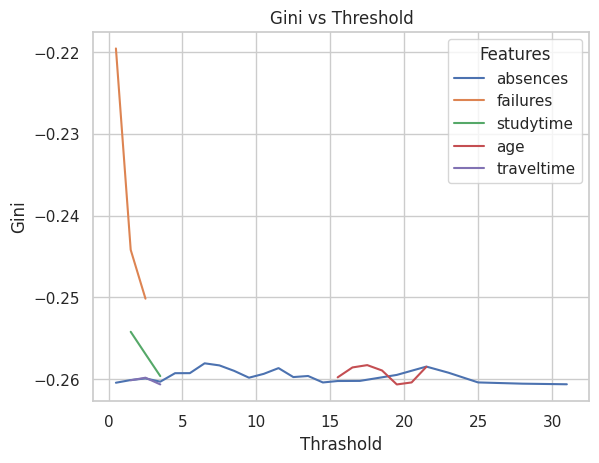

In [ ]:
features = ['absences', 'failures', 'studytime', 'age', 'traveltime']

plt.figure()

for feature in features:
  thresholds, ginis, threshold_best, gini_best = find_best_split(
      student_df[feature],
      student_df['pass']
  )

  plt.plot(thresholds, ginis, label=feature)

plt.xlabel('Thrashold')
plt.ylabel('Gini')
plt.title('Gini vs Threshold')
plt.legend(title='Features')
plt.grid(True)
plt.show()

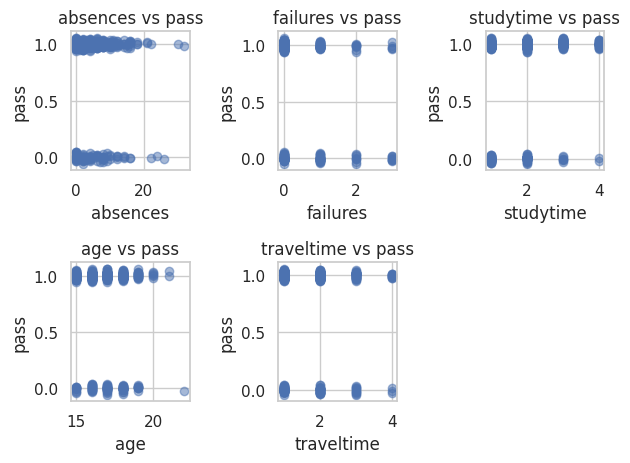

In [ ]:
plt.figure()

for i, feature in enumerate(features, 1):
  plt.subplot(2, 3, i)

  x = student_df[feature]
  y = student_df['pass']

  jitter = np.random.normal(0, 0.02, size=len(y))

  plt.scatter(x, y + jitter, alpha=0.5)
  plt.xlabel(feature)
  plt.ylabel('pass')
  plt.title(f'{feature} vs pass')

plt.tight_layout()
plt.show()

### Задание 5

1. _По какому признаку нужно производить деление выборки на два поддерева? Почему?_

Среди выбранных мной признаков, деление выборки нужно проводить по `failures`, так как для него достигается наименьшее значение gini.


2. _Согласуется ли этот результат с тем, что видно на scatter-графиках? Совпадают ли выводы?_

Результат согласуется, видно что, чем больше становится значение `failures` тем реже встречается `pass` равный 1.

3. _Как выглядят кривые для тех признаков, по которым классы разделяются почти идеально? Чем отличаются от них кривые для признаков, по которым деление практически невозможно?_

Кривые с явно выраженным минимумом более "крутые". Более пологие кривые показывают что при изменении порога gini почти не меняется.

### Задание 6.

Исправленный `_fit_node`:

In [ ]:
    def _fit_node(self, sub_X, sub_y, node):
        if np.all(sub_y == sub_y[0]):
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return

        feature_best, threshold_best, gini_best, split = None, None, None, None
        for feature in range(sub_X.shape[1]):
            feature_type = self._feature_types[feature]
            categories_map = {}

            if feature_type == "real":
                feature_vector = sub_X[:, feature]
            elif feature_type == "categorical":
                counts = Counter(sub_X[:, feature])
                clicks = Counter(sub_X[sub_y == 1, feature])
                ratio = {}
                for key, current_count in counts.items():
                    if key in clicks:
                        current_click = clicks[key]
                    else:
                        current_click = 0
                    ratio[key] = current_click / current_count
                sorted_categories = list(map(lambda x: x[0], sorted(ratio.items(), key=lambda x: x[1])))
                categories_map = dict(zip(sorted_categories, list(range(len(sorted_categories)))))

                feature_vector = np.array(list(map(lambda x: categories_map[x], sub_X[:, feature])))
            else:
                raise ValueError

            if len(feature_vector) == 1:
                continue

            _, _, threshold, gini = find_best_split(feature_vector, sub_y)
            if gini_best is None or gini > gini_best:
                feature_best = feature
                gini_best = gini
                split = feature_vector < threshold

                if feature_type == "real":
                    threshold_best = threshold
                elif feature_type == "Categorical":
                    threshold_best = list(map(lambda x: x[0],
                                              filter(lambda x: x[1] < threshold, categories_map.items())))
                else:
                    raise ValueError

        if feature_best is None:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        node["type"] = "nonterminal"

        node["feature_split"] = feature_best
        if self._feature_types[feature_best] == "real":
            node["threshold"] = threshold_best
        elif self._feature_types[feature_best] == "categorical":
            node["categories_split"] = threshold_best
        else:
            raise ValueError
        node["left_child"], node["right_child"] = {}, {}
        self._fit_node(sub_X[split], sub_y[split], node["left_child"])
        self._fit_node(sub_X[np.logical_not(split)], sub_y[np.logical_not(split)], node["right_child"])

`_predict_node`:

In [ ]:
    def _predict_node(self, x, node):
        if node['type'] == 'terminal':
            return node['class']

        feature = node['feature_split']

        if self._feature_types[feature] == 'real':
            if x[feature] < node['threshold']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        elif self._feature_types[feature] == 'categorical':
            if x[feature] in node['categories_split']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        else:
            raise ValueError

### Задание 7.

In [ ]:
mushrooms_df = pd.read_csv('agaricus-lepiota.data')

mushrooms_df.sample(5)

,p,x,s,n,t,p.1,f,c,n.1,k,...,s.2,w,w.1,p.2,w.2,o,p.3,k.1,s.3,u
3859,e,x,y,n,t,n,f,c,b,n,...,s,w,w,p,w,o,p,n,v,d
5475,p,x,y,g,f,f,f,c,b,h,...,k,n,b,p,w,o,l,h,v,g
3225,p,x,f,g,f,f,f,c,b,p,...,k,p,b,p,w,o,l,h,y,p
7996,p,k,s,n,f,y,f,c,n,b,...,k,p,p,p,w,o,e,w,v,l
6303,p,k,s,n,f,s,f,c,n,b,...,k,p,p,p,w,o,e,w,v,d


Применим LabelEncoder ко всем столбцам:

In [ ]:
label_encoders = {}

for col in mushrooms_df.columns:
  if mushrooms_df[col].dtype == 'object':
    le = LabelEncoder()
    mushrooms_df[col] = le.fit_transform(mushrooms_df[col])
    label_encoders[col] = le

mushrooms_df.sample(5)

,p,x,s,n,t,p.1,f,c,n.1,k,...,s.2,w,w.1,p.2,w.2,o,p.3,k.1,s.3,u
1166,0,5,0,4,1,5,1,0,0,7,...,2,6,6,0,2,1,4,2,5,0
176,0,0,3,9,1,0,1,0,0,2,...,2,7,7,0,2,1,4,3,3,1
2711,0,5,0,2,1,5,1,0,0,9,...,2,3,6,0,2,1,4,3,5,0
2119,0,5,0,2,1,5,1,0,0,7,...,2,7,7,0,2,1,4,3,5,0
4958,1,2,0,3,0,2,1,0,0,2,...,1,6,6,0,2,1,2,1,5,4


Разделим на train и test в отношении 1:1

In [ ]:

mush_X = mushrooms_df.drop(columns=['p'])
mush_y = mushrooms_df['p']

mush_X_train, mush_X_test, mush_y_train, mush_y_test = train_test_split(
    mush_X, mush_y,
    test_size=0.5,
    random_state=42
)


In [ ]:
import numpy as np
from collections import Counter


def find_best_split(feature_vector, target_vector):
    order = np.argsort(feature_vector)
    x = feature_vector[order]
    y = target_vector[order]

    mask = x[:-1] != x[1:]
    thresholds = (x[:-1][mask] + x[1:][mask]) / 2

    if len(thresholds) == 0:
        return thresholds, np.array([]), None, None

    y = y.astype(int)

    left_count = np.arange(1, len(y))
    right_count = len(y) - left_count

    left_positive = np.cumsum(y)[:-1]
    right_positive = np.sum(y) - left_positive

    left_negative = left_count - left_positive
    right_negative = right_count - right_positive

    h_left = 1 - (left_positive / left_count) ** 2 - (left_negative / left_count) ** 2
    h_right = 1 - (right_positive / right_count) ** 2 - (right_negative / right_count) ** 2

    ginis = - (left_count / len(y)) * h_left - (right_count / len(y)) * h_right
    ginis = ginis[mask]

    best_idx = np.argmax(ginis)
    threshold_best = thresholds[best_idx]
    gini_best = ginis[best_idx]

    return thresholds, ginis, threshold_best, gini_best

class DecisionTree:
    """
    Простое классификационное дерево, поддерживающее:
    * real / categorical признаки
    * binary цели (метки могут быть числами или строками)
    * ограничения max_depth, min_samples_split, min_samples_leaf (как в sklearn по смыслу)

    ВНИМАНИЕ: в методе _fit_node ниже могут быть намеренно оставлены некоторые ошибки.
    Их нужно исправить в рамках задания.
    """
    def __init__(self, feature_types, max_depth=None, min_samples_split=None, min_samples_leaf=None):
        if np.any(list(map(lambda x: x != "real" and x != "categorical", feature_types))):
            raise ValueError("There is unknown feature type")

        self._tree = {}
        self._feature_types = feature_types
        self._max_depth = max_depth
        self._min_samples_split = min_samples_split
        self._min_samples_leaf = min_samples_leaf

    def _fit_node(self, sub_X, sub_y, node):
        if np.all(sub_y == sub_y[0]):
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return

        feature_best, threshold_best, gini_best, split = None, None, None, None
        for feature in range(sub_X.shape[1]):
            feature_type = self._feature_types[feature]
            categories_map = {}

            if feature_type == "real":
                feature_vector = sub_X[:, feature]
            elif feature_type == "categorical":
                counts = Counter(sub_X[:, feature])
                clicks = Counter(sub_X[sub_y == 1, feature])
                ratio = {}
                for key, current_count in counts.items():
                    if key in clicks:
                        current_click = clicks[key]
                    else:
                        current_click = 0
                    ratio[key] = current_click / current_count
                sorted_categories = list(map(lambda x: x[0], sorted(ratio.items(), key=lambda x: x[1])))
                categories_map = dict(zip(sorted_categories, list(range(len(sorted_categories)))))

                feature_vector = np.array(list(map(lambda x: categories_map[x], sub_X[:, feature])))
            else:
                raise ValueError

            if len(feature_vector) == 1:
                continue

            _, _, threshold, gini = find_best_split(feature_vector, sub_y)

            if threshold is None:
                continue
            if gini_best is None or gini > gini_best:
                feature_best = feature
                gini_best = gini
                split = feature_vector < threshold

                if feature_type == "real":
                    threshold_best = threshold
                elif feature_type == "Categorical":
                    threshold_best = list(map(lambda x: x[0],
                                              filter(lambda x: x[1] < threshold, categories_map.items())))
                else:
                    raise ValueError

        if feature_best is None:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        node["type"] = "nonterminal"

        node["feature_split"] = feature_best
        if self._feature_types[feature_best] == "real":
            node["threshold"] = threshold_best
        elif self._feature_types[feature_best] == "categorical":
            node["categories_split"] = threshold_best
        else:
            raise ValueError
        node["left_child"], node["right_child"] = {}, {}
        self._fit_node(sub_X[split], sub_y[split], node["left_child"])
        self._fit_node(sub_X[np.logical_not(split)], sub_y[np.logical_not(split)], node["right_child"])

    def _predict_node(self, x, node):
        if node['type'] == 'terminal':
            return node['class']

        feature = node['feature_split']

        if self._feature_types[feature] == 'real':
            if x[feature] < node['threshold']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        elif self._feature_types[feature] == 'categorical':
            if x[feature] in node['categories_split']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        else:
            raise ValueError

    def fit(self, X, y):
        self._fit_node(X, y, self._tree)

    def predict(self, X):
        predicted = []
        for x in X:
            predicted.append(self._predict_node(x, self._tree))
        return np.array(predicted)

Обучем дерево с помощью написанного класса:


In [ ]:
mush_X_train = np.asarray(mush_X_train)
mush_X_test = np.asarray(mush_X_test)

mush_y_train = np.asarray(mush_y_train)
mush_y_test = np.asarray(mush_y_test)

tree = DecisionTree(feature_types=['real'] * mush_X_train.shape[1])
tree.fit(mush_X_train, mush_y_train)

mush_y_pred = tree.predict(mush_X_test)

print('Accuracy:', accuracy_score(mush_y_test, mush_y_pred))

Accuracy: 1.0


### Задание 8.

Добавим поддержку параметров `max_depth`, `min_samples_split` и `min_samples_leaf` по аналогии с `sklearn.tree.DecisionTreeClassifier`.

In [ ]:
import numpy as np
from collections import Counter


def find_best_split(feature_vector, target_vector):
    order = np.argsort(feature_vector)
    x = feature_vector[order]
    y = target_vector[order]

    mask = x[:-1] != x[1:]
    thresholds = (x[:-1][mask] + x[1:][mask]) / 2

    if len(thresholds) == 0:
        return thresholds, np.array([]), None, None

    y = y.astype(int)

    left_count = np.arange(1, len(y))
    right_count = len(y) - left_count

    left_positive = np.cumsum(y)[:-1]
    right_positive = np.sum(y) - left_positive

    left_negative = left_count - left_positive
    right_negative = right_count - right_positive

    h_left = 1 - (left_positive / left_count) ** 2 - (left_negative / left_count) ** 2
    h_right = 1 - (right_positive / right_count) ** 2 - (right_negative / right_count) ** 2

    ginis = - (left_count / len(y)) * h_left - (right_count / len(y)) * h_right
    ginis = ginis[mask]

    best_idx = np.argmax(ginis)
    threshold_best = thresholds[best_idx]
    gini_best = ginis[best_idx]

    return thresholds, ginis, threshold_best, gini_best

class DecisionTree:
    """
    Простое классификационное дерево, поддерживающее:
    * real / categorical признаки
    * binary цели (метки могут быть числами или строками)
    * ограничения max_depth, min_samples_split, min_samples_leaf (как в sklearn по смыслу)

    ВНИМАНИЕ: в методе _fit_node ниже могут быть намеренно оставлены некоторые ошибки.
    Их нужно исправить в рамках задания.
    """
    def __init__(self, feature_types, max_depth=None, min_samples_split=2, min_samples_leaf=1):
        if np.any(list(map(lambda x: x != "real" and x != "categorical", feature_types))):
            raise ValueError("There is unknown feature type")

        self._tree = {}
        self._feature_types = feature_types
        self._max_depth = max_depth
        self._min_samples_split = min_samples_split
        self._min_samples_leaf = min_samples_leaf

    def _fit_node(self, sub_X, sub_y, node, depth):
        if (
            np.all(sub_y == sub_y[0])
            or len(sub_y) < self._min_samples_split
            or (self._max_depth is not None and depth >= self._max_depth)
        ):
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return

        feature_best, threshold_best, gini_best, split = None, None, None, None
        for feature in range(sub_X.shape[1]):
            feature_type = self._feature_types[feature]
            categories_map = {}

            if feature_type == "real":
                feature_vector = sub_X[:, feature]
            elif feature_type == "categorical":
                counts = Counter(sub_X[:, feature])
                clicks = Counter(sub_X[sub_y == 1, feature])
                ratio = {}
                for key, current_count in counts.items():
                    if key in clicks:
                        current_click = clicks[key]
                    else:
                        current_click = 0
                    ratio[key] = current_click / current_count
                sorted_categories = list(map(lambda x: x[0], sorted(ratio.items(), key=lambda x: x[1])))
                categories_map = dict(zip(sorted_categories, list(range(len(sorted_categories)))))

                feature_vector = np.array(list(map(lambda x: categories_map[x], sub_X[:, feature])))
            else:
                raise ValueError

            if len(feature_vector) == 1:
                continue

            _, _, threshold, gini = find_best_split(feature_vector, sub_y)

            if threshold is None:
                continue

            curr_split = feature_vector < threshold

            left_size = np.sum(curr_split)
            right_size = np.sum(np.logical_not(curr_split))

            if left_size < self._min_samples_leaf or right_size < self._min_samples_leaf:
                continue

            if gini_best is None or gini > gini_best:
                feature_best = feature
                gini_best = gini
                split = feature_vector < threshold

                if feature_type == "real":
                    threshold_best = threshold
                elif feature_type == "Categorical":
                    threshold_best = list(map(lambda x: x[0],
                                              filter(lambda x: x[1] < threshold, categories_map.items())))
                else:
                    raise ValueError

        if feature_best is None:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        node["type"] = "nonterminal"

        node["feature_split"] = feature_best
        if self._feature_types[feature_best] == "real":
            node["threshold"] = threshold_best
        elif self._feature_types[feature_best] == "categorical":
            node["categories_split"] = threshold_best
        else:
            raise ValueError
        node["left_child"], node["right_child"] = {}, {}
        self._fit_node(sub_X[split], sub_y[split], node["left_child"], depth + 1)
        self._fit_node(sub_X[np.logical_not(split)], sub_y[np.logical_not(split)], node["right_child"], depth + 1)

    def _predict_node(self, x, node):
        if node['type'] == 'terminal':
            return node['class']

        feature = node['feature_split']

        if self._feature_types[feature] == 'real':
            if x[feature] < node['threshold']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        elif self._feature_types[feature] == 'categorical':
            if x[feature] in node['categories_split']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        else:
            raise ValueError

    def fit(self, X, y):
        self._fit_node(X, y, self._tree, depth=0)

    def predict(self, X):
        predicted = []
        for x in X:
            predicted.append(self._predict_node(x, self._tree))
        return np.array(predicted)


### Задание 9.

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

np.random.seed(0)

wine_quality = fetch_ucirepo(id=186)

In [ ]:
df = wine_quality.data.original.sample(frac=0.1)

X = df.drop(columns=['color'])
y = df['color']

In [ ]:

X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 650 entries, 5316 to 5545
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         650 non-null    float64
 1   volatile_acidity      650 non-null    float64
 2   citric_acid           650 non-null    float64
 3   residual_sugar        650 non-null    float64
 4   chlorides             650 non-null    float64
 5   free_sulfur_dioxide   650 non-null    float64
 6   total_sulfur_dioxide  650 non-null    float64
 7   density               650 non-null    float64
 8   pH                    650 non-null    float64
 9   sulphates             650 non-null    float64
 10  alcohol               650 non-null    float64
 11  quality               650 non-null    int64  
dtypes: float64(11), int64(1)
memory usage: 66.0 KB


In [ ]:
y.info()

<class 'pandas.core.series.Series'>
Index: 650 entries, 5316 to 5545
Series name: color
Non-Null Count  Dtype 
--------------  ----- 
650 non-null    object
dtypes: object(1)
memory usage: 10.2+ KB


In [ ]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

X12_train = np.asarray(X_train)
X12_test = np.asarray(X_test)

y12_train = np.asarray(y_train)
y12_test = np.asarray(y_test)

tree1 = DecisionTree(feature_types=['real'] * X12_train.shape[1])
tree1.fit(X12_train, y12_train)
pred1 = tree1.predict(X12_test)

tree2 = DecisionTree(feature_types=['real'] * X12_train.shape[1], max_depth=8, min_samples_leaf=5, min_samples_split=17)
tree2.fit(X12_train, y12_train)
pred2 = tree2.predict(X12_test)

tree3 = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, min_samples_split=17)
tree3.fit(X_train, y_train)
pred3 = tree3.predict(X_test)

In [ ]:
print(classification_report(y_test, pred1))

              precision    recall  f1-score   support

           0       0.86      0.94      0.90        52
           1       0.98      0.94      0.96       143

    accuracy                           0.94       195
   macro avg       0.92      0.94      0.93       195
weighted avg       0.95      0.94      0.94       195



In [ ]:
print(classification_report(y_test, pred2))

              precision    recall  f1-score   support

           0       0.83      0.94      0.88        52
           1       0.98      0.93      0.95       143

    accuracy                           0.93       195
   macro avg       0.90      0.94      0.92       195
weighted avg       0.94      0.93      0.93       195



In [ ]:
print(classification_report(y_test, pred3))

              precision    recall  f1-score   support

           0       0.89      0.94      0.92        52
           1       0.98      0.96      0.97       143

    accuracy                           0.95       195
   macro avg       0.93      0.95      0.94       195
weighted avg       0.96      0.95      0.95       195



Для нашего дерева с дефолтными и заданными параметрами есть незначительная разница, с заданными параметрами метрики немного хуже. Вероятнее всего это связано с тем, что с дефолтными параметрами дерево может строить более глубокие ветки, делить маленькие группы объектов и создавать листья по 1-2 объекта, то есть оно лучше подстраивается под данные. Но изменения совсем незначительные, так что кажется ограничения не сильно сказались на качестве. Но при этом такие ограничения делают модель более устойчивой и менее склонной к переобучению.

# Bias-variance decomposition

## Вычисление bias и variance

### Задание 10.1

In [ ]:
from sklearn.datasets import fetch_california_housing

california = fetch_california_housing()
X = california["data"]
y = california["target"]

X.shape, y.shape

((20640, 8), (20640,))

In [ ]:
def compute_biase_variance(model, X, y, num_runs=1000):
    X = np.asarray(X)
    y = np.asarray(y)

    n_obj = X.shape[0]

    pred_sum = np.zeros(n_obj)
    pred_sq_sum = np.zeros(n_obj)
    pred_count = np.zeros(n_obj, dtype=int)

    error_sum = 0.0
    error_count = 0

    for _ in range(num_runs):
        bootstrap_idx = np.random.randint(0, n_obj, size=n_obj)

        oob_mask = np.ones(n_obj, dtype=bool)
        oob_mask[bootstrap_idx] = False

        if not np.any(oob_mask):
            continue

        alg = clone(model)
        alg.fit(X[bootstrap_idx], y[bootstrap_idx])

        preds = alg.predict(X[oob_mask])
        true = y[oob_mask]

        pred_sum[oob_mask] += preds
        pred_sq_sum[oob_mask] += preds ** 2
        pred_count[oob_mask] += 1

        error_sum += np.sum((preds - true) ** 2)
        error_count += preds.shape[0]

    valid_bias = pred_count > 0

    mean_preds = np.zeros(n_obj)
    mean_preds[valid_bias] = pred_sum[valid_bias] / pred_count[valid_bias]

    bias = np.mean((mean_preds[valid_bias] - y[valid_bias]) ** 2)

    valid_var = pred_count > 1

    variance_per_object = (pred_sq_sum[valid_var] - pred_sum[valid_var] ** 2 / pred_count[valid_var]) / (pred_count[valid_var] - 1)

    variance = np.mean(variance_per_object)

    error = error_sum / error_count

    return bias, variance, error

### Задание 10.2

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
bias, variance, error = compute_biase_variance(
    model=lr,
    X=X,
    y=y,
    num_runs=100
)

print('Linear Regression Bias:', bias)
print('Linear Regression Variance:', variance)
print(f'Linear Regression Error:', error)

Linear Regression Bias: 0.5627221059878915
Linear Regression Variance: 0.21433726277566986
Linear Regression Error: 0.7716690165968


In [ ]:
from sklearn.tree import DecisionTreeRegressor

dtr = DecisionTreeRegressor()
bias, variance, error = compute_biase_variance(
    model=dtr,
    X=X,
    y=y,
    num_runs=100
)

print('Decision Tree Regressor Bias:', bias)
print('Decision Tree Regressor Variance:', variance)
print(f'Decision Tree Regressor Error:', error)

Decision Tree Regressor Bias: 0.24805051935998104
Decision Tree Regressor Variance: 0.30007647195273857
Decision Tree Regressor Error: 0.5403814120345312


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rfr = RandomForestRegressor()
bias, variance, error = compute_biase_variance(
    model=rfr,
    X=X,
    y=y,
    num_runs=100
)

print('Random Forest Regressor Bias:', bias)
print('Random Forest Regressor Variance:', variance)
print(f'Random Forest Regressor Error:', error)

Random Forest Regressor Bias: 0.2470647834027655
Random Forest Regressor Variance: 0.018925850136932387
Random Forest Regressor Error: 0.2657751812283668


`Linear Regression`: самое большое смещение, но относительно небольшая дисперсия, ошибка самая большая. Видимо, линейная регрессия - слишком простая модель для этих данных. Не может уловить нелинейности, но при этом предсказания между bootstrap выборками стабильны.


`Decision Tree Regressor`: смещение сильно ниже, но при этом выросла дисперсия, ошибка уменьшилась. Этот результат показывает, что дерево гораздо лучше справляется с нелинейностями, поэтому bias в разы меньше. Но при этом дерево очень чувствительно к данным, изменение выборки сильно влияет на структуру дерева, отсюда высокое значение дисперсии.


`Random Forest Regressor`: лучший результат, смещение почти такое же как у одного дерева, но при этом дисперсия заметно меньше, ошибка - минимальная. Так происходит потому что случайный лес обучает много деревьев и предсказания усредняются, отсюда улучшение дисперсии.

### Задание 10.3

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

In [ ]:
from sklearn.ensemble import BaggingRegressor

model = BaggingRegressor(estimator=LinearRegression())
bias, variance, error = compute_biase_variance(
    model=model,
    X=X,
    y=y,
    num_runs=100
)

print('Linear Regression Bagging Bias:', bias)
print('Linear Regression Bagging Variance:', variance)
print(f'Linear Regression Bagging Error:', error)

Linear Regression Bagging Bias: 0.6201388402119882
Linear Regression Bagging Variance: 0.19275916779887906
Linear Regression Bagging Error: 0.8551686354328624


In [ ]:
from sklearn.tree import DecisionTreeRegressor

model = BaggingRegressor(estimator=DecisionTreeRegressor())
bias, variance, error = compute_biase_variance(
    model=model,
    X=X,
    y=y,
    num_runs=100
)

print('Decision Tree Regressor Bagging Bias:', bias)
print('Decision Tree Regressor Bagging Variance:', variance)
print(f'Decision Tree Regressor Bagging Error:', error)

Decision Tree Regressor Bagging Bias: 0.2467042051076313
Decision Tree Regressor Bagging Variance: 0.04630857271810131
Decision Tree Regressor Bagging Error: 0.2912667909643176


In [ ]:
model = BaggingRegressor(estimator=RandomForestRegressor())
bias, variance, error = compute_biase_variance(
    model=model,
    X=X,
    y=y,
    num_runs=100
)

print('Random Forest Regressor Bagging Bias:', bias)
print('Random Forest Regressor Bagging Variance:', variance)
print(f'Random Forest Regressor Bagging Error:', error)

KeyboardInterrupt: 

## Визуализация предсказаний базовых алгоритмов бэггинга

### Задание 11.1

In [ ]:
def plot_predictions(model, X, y, num_runs=100, num_test_objects=10, title="", show_bias_variance=True, ax=None):
    rng = np.random.RandomState()

    test_indices = rng.choice(len(X), size=num_test_objects, replace=False)

    all_indices = np.arange(len(X))
    train_indices = np.setdiff1d(all_indices, test_indices)

    X_test = X.iloc[test_indices] if hasattr(X, 'iloc') else X[test_indices]
    y_test = y.iloc[test_indices] if hasattr(y, 'iloc') else y[test_indices]

    X_train = X.iloc[train_indices] if hasattr(X, 'iloc') else X[train_indices]
    y_train = y.iloc[train_indices] if hasattr(y, 'iloc') else y[train_indices]

    y_test = np.asarray(y_test)

    predictions = []

    for _ in range(num_runs):
        bootstrap_indices = rng.choice(len(X_train), size=len(X_train), replace=True)

        X_boot = X_train.iloc[bootstrap_indices] if hasattr(X_train, 'iloc') else X_train[bootstrap_indices]
        y_boot = y_train.iloc[bootstrap_indices] if hasattr(y_train, 'iloc') else y_train[bootstrap_indices]

        model_copy = clone(model)
        model_copy.fit(X_boot, y_boot)

        pred = model_copy.predict(X_test)
        predictions.append(pred)

    predictions = np.array(predictions)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    x_positions = np.arange(num_test_objects)

    for i in range(num_test_objects):
        ax.scatter(
            np.full(num_runs, i),
            predictions[:, i],
            alpha=0.5
        )

    ax.scatter(
        x_positions,
        y_test,
        color='black',
        s=80,
        zorder=10,
        label='True Value'
    )

    ax.set_xlabel('Test object index')
    ax.set_ylabel('Prediction')
    ax.set_title(title or model.__class__.__name__)

    return ax

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
    sharey=True
)

models = [
    ('Linear Regression', LinearRegression()),
    ('Decision Tree', DecisionTreeRegressor(random_state=42)),
    ('Random Forest', RandomForestRegressor(random_state=42))
]

for ax, (title, model) in zip(axes, models):
    plot_predictions(
        model,
        X,
        y,
        title=title,
        ax=ax
    )

plt.suptitle('Comparison of Prediction Variance')
plt.tight_layout()
plt.show()